# OutlierTrimmer: remove extreme observations

`OutlierTrimmer` removes rows that contain outliers according to a statistical rule. This differs from capping: the values are not changed; the observations are excluded from the returned dataframe.

This notebook uses the house-price data to demonstrate IQR trimming, visualise which rows are removed, and compare IQR with a quantile rule.

## When should rows be removed?

Trimming can help when extreme records are known errors, outside the population of interest, or so influential that they distort the intended analysis. It is risky when rare values are genuine and important. The trimming decision must be made from training data and should be recorded because the dataset size changes.

In [1]:
import importlib.util, subprocess, sys
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn", "sklearn": "scikit-learn", "feature_engine": "feature-engine"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from feature_engine.outliers import OutlierTrimmer
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load and inspect the data

We select complete numeric columns so the outlier transformer can learn limits without a separate imputation step. In a production pipeline, imputation and outlier handling should be ordered deliberately.

,LotArea,GrLivArea,TotalBsmtSF,SalePrice
count,1460.0,1460.0,1460.0,1460.0
mean,10516.8,1515.5,1057.4,180921.2
std,9981.3,525.5,438.7,79442.5
min,1300.0,334.0,0.0,34900.0
25%,7553.5,1129.5,795.8,129975.0
50%,9478.5,1464.0,991.5,163000.0
75%,11601.5,1776.8,1298.2,214000.0
max,215245.0,5642.0,6110.0,755000.0


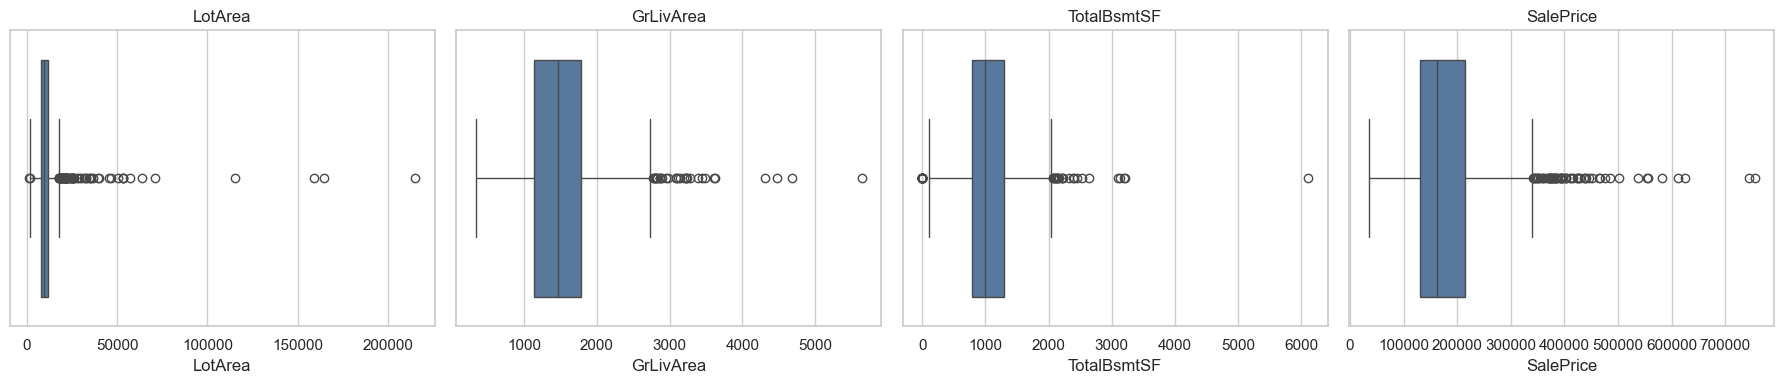

In [2]:
paths = [Path("houseprice.csv"), Path("../imputation/houseprice.csv"), Path("feature-engineering/imputation/houseprice.csv")]
path = next((p for p in paths if p.exists()), None)
if path is None: raise FileNotFoundError("Could not find houseprice.csv")
data = pd.read_csv(path)
features = ["LotArea", "GrLivArea", "TotalBsmtSF", "SalePrice"]
data[features] = data[features].apply(pd.to_numeric, errors="coerce")
data = data.dropna(subset=features).reset_index(drop=True)
display(data[features].describe().round(1))
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x=data[col], ax=ax, color="#4C78A8"); ax.set_title(col)
plt.tight_layout(); plt.show()

## 2. Split before detecting outliers

The IQR boundaries are learned from the training rows. The test rows are then filtered using those same boundaries. This prevents the test distribution from changing which observations are considered outliers.

In [3]:
X = data[features].copy()
X_train, X_test = train_test_split(X, test_size=0.30, random_state=0)
trimmer = OutlierTrimmer(capping_method="iqr", tail="both", fold=1.5, variables=features)
trimmer.fit(X_train)
X_train_trimmed = trimmer.transform(X_train)
X_test_trimmed = trimmer.transform(X_test)
limits = pd.DataFrame({"lower_limit": pd.Series(trimmer.left_tail_caps_), "upper_limit": pd.Series(trimmer.right_tail_caps_)})
display(limits)
print(f"Training rows: {len(X_train):,} -> {len(X_train_trimmed):,}")
print(f"Test rows: {len(X_test):,} -> {len(X_test_trimmed):,}")

,lower_limit,upper_limit
LotArea,1962.250,17376.250
GrLivArea,165.625,2764.625
TotalBsmtSF,94.875,1985.875
SalePrice,3581.250,341531.250


Training rows: 1,022 -> 887
Test rows: 438 -> 368


## 3. Understand which rows were removed

An observation is removed if it is an outlier in at least one selected variable. The index difference lets us identify removed records and inspect whether the rule is behaving as expected.

In [4]:
removed_train = X_train.index.difference(X_train_trimmed.index)
removed_test = X_test.index.difference(X_test_trimmed.index)
print("Removed training rows:", len(removed_train), f"({len(removed_train)/len(X_train):.1%})")
print("Removed test rows:", len(removed_test), f"({len(removed_test)/len(X_test):.1%})")
display(X_train.loc[removed_train].head(10))
display(X_train.loc[removed_train].describe().round(1))

Removed training rows: 135 (13.2%)
Removed test rows: 70 (16.0%)


,LotArea,GrLivArea,TotalBsmtSF,SalePrice
11,11924,2324,1175,345000
17,10791,1296,0,90000
66,19900,2207,1947,180000
90,7200,1040,0,109900
102,7018,1535,0,118964
112,9965,2696,1264,383970
118,12376,3222,1673,320000
120,21453,988,938,180000
151,13891,1710,1710,372402
171,31770,1656,1080,215000


,LotArea,GrLivArea,TotalBsmtSF,SalePrice
count,135.0,135.0,135.0,135.0
mean,19402.6,1943.7,1183.4,247836.3
std,25641.1,786.3,775.6,138576.3
min,1300.0,334.0,0.0,39300.0
25%,9586.0,1380.0,630.0,119232.0
50%,13891.0,1902.0,1324.0,239000.0
75%,21091.0,2375.0,1728.0,359550.0
max,215245.0,4676.0,3206.0,755000.0


In [ ]:
fig, axes = plt.subplots(2, len(features), figsize=(18, 8))
for i, col in enumerate(features):
    sns.boxplot(x=X_train[col], ax=axes[0, i], color="#4C78A8"); axes[0, i].set_title(f"All training rows: {col}")
    sns.boxplot(x=X_train_trimmed[col], ax=axes[1, i], color="#54A24B"); axes[1, i].set_title(f"After trimming: {col}")
plt.tight_layout(); plt.show()

## 4. Compare IQR and quantile trimming

The quantile rule removes a fixed tail percentage, whereas IQR limits depend on quartile spread. The choice affects the number of retained rows and should reflect the goal of the analysis.

In [5]:
quantile_trimmer = OutlierTrimmer(capping_method="quantiles", tail="both", fold=0.05, variables=features)
quantile_trimmer.fit(X_train)
X_train_quantile = quantile_trimmer.transform(X_train)
comparison = pd.DataFrame({"method": ["IQR (1.5 × IQR)", "Quantiles (5% each tail)"], "rows_retained": [len(X_train_trimmed), len(X_train_quantile)]})
comparison["rows_removed"] = len(X_train) - comparison["rows_retained"]
display(comparison)

,method,rows_retained,rows_removed
0,IQR (1.5 × IQR),887,135
1,Quantiles (5% each tail),725,297


## Summary and cautions

`OutlierTrimmer` removes rows rather than changing their values. It can improve robustness when extremes are invalid or outside the target population, but it can also remove legitimate rare observations and alter class or subgroup composition. Fit the rule on training data only, report how many rows were removed, inspect the records, and compare results with capping or no outlier handling.